In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

De un proyecto con presupuesto total BAC = 320 k€ y duración planificada de 20 semanas sólo se dispone del informe de seguimiento adjunto: los valores acumulados al final de cada semana, hasta la 14, del valor planificado (PV), el valor ganado (EV) y el coste real (AC), en k€. No se conoce el cuadro de actividades.

In [4]:
pregunta_1 = "1. Dibuje las tres curvas S. Calcule CV, SV, CPI y SPI en cada semana y represente la evolución de los dos índices.  "
pregunta_2 = "2. ¿En qué semana empezó el proyecto a retrasarse? ¿Y a tener sobrecoste? ¿Fueron simultáneos?  "
pregunta_3 = "3. Con los datos de la semana 14, estime el coste final (EAC = BAC / CPI) y la duración final por programación ganada: ES es la semana en que el PV planificado alcanzaba el EV actual; SPI(t) = ES / semana; duración ≈ duración planificada / SPI(t).  "
pregunta_4 = "4. ¿Qué no puede saberse sin el cuadro de actividades? Ponga un ejemplo de dos situaciones distintas que darían las mismas curvas.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Dibuje las tres curvas S. Calcule CV, SV, CPI y SPI en cada semana y represente la evolución de los dos índices.  

2. ¿En qué semana empezó el proyecto a retrasarse? ¿Y a tener sobrecoste? ¿Fueron simultáneos?  

3. Con los datos de la semana 14, estime el coste final (EAC = BAC / CPI) y la duración final por programación ganada: ES es la semana en que el PV planificado alcanzaba el EV actual; SPI(t) = ES / semana; duración ≈ duración planificada / SPI(t).  

4. ¿Qué no puede saberse sin el cuadro de actividades? Ponga un ejemplo de dos situaciones distintas que darían las mismas curvas.  

In [5]:
#| tbl-cap: "Informe de seguimiento (valores acumulados, k€)"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  week, PV   , EV   , AC 
    (1   , 18.7 , 18.5 , 22 ),
    (2   , 37.3 , 37.5 , 44 ),
    (3   , 56   , 56   , 67 ),
    (4   , 69.2 , 67.6 , 83 ),
    (5   , 82.5 , 79.5 , 99 ),
    (6   , 93.8 , 89.4 , 113),
    (7   , 105  , 99   , 127),
    (8   , 108.8, 108.6, 140),
    (9   , 112.5, 112.5, 145),
    (10  , 116.2, 116.4, 150),
    (11  , 120  , 120  , 155),
    (12  , 138  , 129.8, 165),
    (13  , 161  , 140  , 177),
    (14  , 184  , 157.2, 198),
], columns=['week', 'PV', 'EV', 'AC']).set_index('week')
datos_enunciado

,PV,EV,AC
week,,,
1,18.7,18.5,22
2,37.3,37.5,44
3,56.0,56.0,67
4,69.2,67.6,83
5,82.5,79.5,99
6,93.8,89.4,113
7,105.0,99.0,127
8,108.8,108.6,140
9,112.5,112.5,145


# Resolución

In [6]:
BAC_total, duracion_planificada = 320, 20
curvas = datos_enunciado.copy().astype(float)

## Apartado 1

In [7]:
display(Markdown(pregunta_1))

1. Dibuje las tres curvas S. Calcule CV, SV, CPI y SPI en cada semana y represente la evolución de los dos índices.  

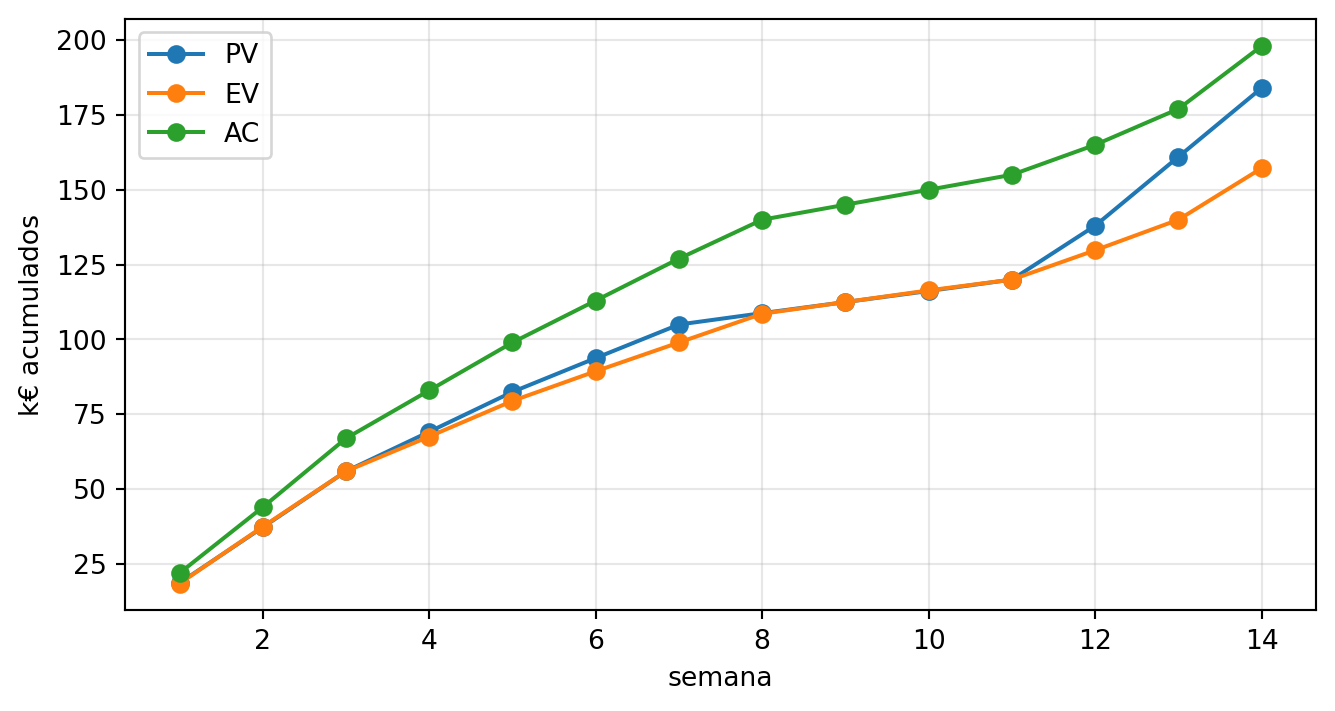

In [8]:
#| fig-cap: "Curvas S del proyecto"
#| label: fig-curvasS
from matplotlib import pyplot as plt
ax = curvas.plot(marker='o', figsize=(8, 4)); ax.set_xlabel('semana'); ax.set_ylabel('k€ acumulados'); ax.grid(alpha=0.3); plt.show()

In [9]:
#| tbl-cap: "Indicadores semana a semana"
#| label: tbl-indicadores
ind = curvas.copy()
ind['CV = EV − AC'] = ind['EV'] - ind['AC']
ind['SV = EV − PV'] = ind['EV'] - ind['PV']
ind['CPI = EV / AC'] = ind['EV'] / ind['AC']
ind['SPI = EV / PV'] = ind['EV'] / ind['PV']
ind.round(3)

,PV,EV,AC,CV = EV − AC,SV = EV − PV,CPI = EV / AC,SPI = EV / PV
week,,,,,,,
1,18.7,18.5,22.0,-3.5,-0.2,0.841,0.989
2,37.3,37.5,44.0,-6.5,0.2,0.852,1.005
3,56.0,56.0,67.0,-11.0,0.0,0.836,1.000
4,69.2,67.6,83.0,-15.4,-1.6,0.814,0.977
5,82.5,79.5,99.0,-19.5,-3.0,0.803,0.964
6,93.8,89.4,113.0,-23.6,-4.4,0.791,0.953
7,105.0,99.0,127.0,-28.0,-6.0,0.780,0.943
8,108.8,108.6,140.0,-31.4,-0.2,0.776,0.998
9,112.5,112.5,145.0,-32.5,0.0,0.776,1.000


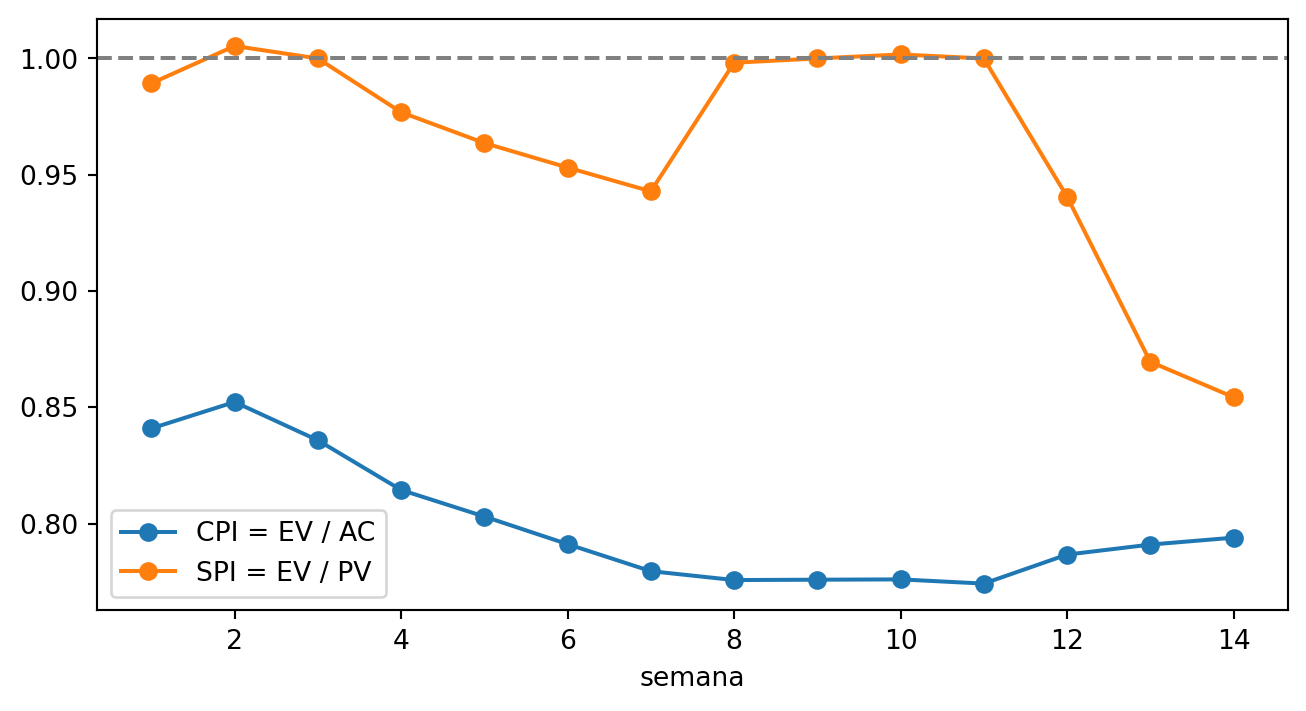

In [10]:
#| fig-cap: "Evolución de CPI y SPI"
#| label: fig-indices
ax = ind[['CPI = EV / AC', 'SPI = EV / PV']].plot(marker='o', figsize=(8, 4)); ax.axhline(1, color='grey', linestyle='--'); ax.set_xlabel('semana'); plt.show()

## Apartado 2

In [11]:
display(Markdown(pregunta_2))

2. ¿En qué semana empezó el proyecto a retrasarse? ¿Y a tener sobrecoste? ¿Fueron simultáneos?  

In [12]:
umbral = 0.97
semana_retraso = next((int(t) for t, v in ind['SPI = EV / PV'].items() if v < umbral), None)
semana_sobrecoste = next((int(t) for t, v in ind['CPI = EV / AC'].items() if v < umbral), None)
Markdown(f'''Tomando como señal un índice por debajo de {umbral}: el retraso aparece en la semana {semana_retraso} (SPI < {umbral}) y el sobrecoste en la semana {semana_sobrecoste} (CPI < {umbral}). {'Fueron simultáneos.' if semana_retraso == semana_sobrecoste else 'No fueron simultáneos: un problema de plazo no implica uno de coste ni al revés (se puede ir despacio gastando poco, o gastar mucho para ir rápido).'}''')

Tomando como señal un índice por debajo de 0.97: el retraso aparece en la semana 5 (SPI < 0.97) y el sobrecoste en la semana 1 (CPI < 0.97). No fueron simultáneos: un problema de plazo no implica uno de coste ni al revés (se puede ir despacio gastando poco, o gastar mucho para ir rápido).

## Apartado 3

In [13]:
display(Markdown(pregunta_3))

3. Con los datos de la semana 14, estime el coste final (EAC = BAC / CPI) y la duración final por programación ganada: ES es la semana en que el PV planificado alcanzaba el EV actual; SPI(t) = ES / semana; duración ≈ duración planificada / SPI(t).  

In [14]:
t = int(curvas.index[-1])
PV, EV, AC = curvas.loc[t, 'PV'], curvas.loc[t, 'EV'], curvas.loc[t, 'AC']
CPI, SPI = EV / AC, EV / PV
EAC = BAC_total / CPI
# programación ganada: ES = semana en que PV alcanzó el EV actual (interpolando)
pv = curvas['PV']
k = int((pv <= EV).sum())           # última semana con PV ≤ EV
if k == 0:
    ES = EV / pv.iloc[0]
elif k >= len(pv):
    ES = float(pv.index[-1])
else:
    ES = k + (EV - pv.iloc[k - 1]) / (pv.iloc[k] - pv.iloc[k - 1])
SPI_t = ES / t
duracion_estimada = duracion_planificada / SPI_t
Markdown(f'''En la semana {t}: CPI = {EV:.1f} / {AC:.1f} = {CPI:.3f}, EAC = {BAC_total:.0f} / {CPI:.3f} = {EAC:.1f} k€ (VAC = {BAC_total - EAC:.1f}).

El PV alcanzaba {EV:.1f} k€ en la semana ES = {ES:.2f} (entre la {k} y la {k + 1}); SPI(t) = {ES:.2f} / {t} = {SPI_t:.3f}; duración estimada = {duracion_planificada} / {SPI_t:.3f} = {duracion_estimada:.1f} semanas, es decir, unas {duracion_estimada - duracion_planificada:.1f} semanas de retraso.''')

En la semana 14: CPI = 157.2 / 198.0 = 0.794, EAC = 320 / 0.794 = 403.1 k€ (VAC = -83.1).

El PV alcanzaba 157.2 k€ en la semana ES = 12.83 (entre la 12 y la 13); SPI(t) = 12.83 / 14 = 0.917; duración estimada = 20 / 0.917 = 21.8 semanas, es decir, unas 1.8 semanas de retraso.

## Apartado 4

In [15]:
display(Markdown(pregunta_4))

4. ¿Qué no puede saberse sin el cuadro de actividades? Ponga un ejemplo de dos situaciones distintas que darían las mismas curvas.  

Las curvas agregan todas las actividades: no dicen *qué* actividades van mal ni si son críticas. Un SPI = 0,85 puede deberse a una actividad crítica retrasada (el plazo final peligra) o a varias no críticas aplazadas dentro de su holgura (el plazo no peligra): las mismas curvas, pronósticos opuestos. Igual con el coste: un CPI bajo puede venir de una actividad ya terminada (el daño está hecho y no se repetirá) o de una en curso (seguirá gastando de más). Por eso el informe debe acompañarse del detalle por actividad.